# 4장 위원회 질의

여러 모델의 불일치로 정보성을 재는 위원회 질의(QBC)를 구현한다. 위원회 구성(배깅, 이종 모델) 두 가지와 불일치 척도(투표 엔트로피, KL 불일치) 두 가지를 비교한다.

- 4.1 버전 공간과 위원회
- 4.2 위원회 구성 — 배깅과 이종 모델
- 4.3 투표 엔트로피(vote entropy)
- 4.4 KL 불일치
- 4.5 위원회 크기와 다양성의 영향
- 4.6 불확실성 샘플링과의 비교

CPU만으로 돈다. 위원 수만큼 학습이 늘어 2·3장보다 오래 걸리므로 (전략, 시드) 조합을 joblib으로 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 결과 수치는 순차 실행과 같다. 다만 여러 작업이 코어를 함께 쓰므로 라운드당 질의 시간(t_query)은 순차 실행보다 조금 길게 잡힐 수 있다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


## 4.2 위원회 구성 — 배깅과 이종 모델

배깅 위원회는 라벨 집합의 부트스트랩 표본마다 로지스틱 회귀를 학습한다. 이종 위원회는 로지스틱 회귀, 다항 나이브 베이즈, 수정 후버 손실 선형 분류기 세 모델로 만든다. 세 모델 모두 확률을 낸다.

In [2]:
# ── 위원회 구성 ────
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import SGDClassifier

def train_bagging_committee(X, y, C, seed):
    rng = np.random.default_rng(seed)
    boots = [rng.choice(len(y), len(y)) for _ in range(C)]
    return [train_model(X[b], y[b], seed + c) for c, b in enumerate(boots)]

def train_hetero_committee(X, y, seed):
    return [train_model(X, y, seed),
            MultinomialNB(alpha=0.1).fit(X, y),
            SGDClassifier(loss="modified_huber", random_state=seed).fit(X, y)]

def committee_proba(members, X, n_classes):
    return np.stack([proba(m, X, n_classes) for m in members])     # (위원, 샘플, 클래스)

## 4.3 투표 엔트로피(vote entropy)

위원마다 1위 클래스에 한 표를 던지고 표 분포의 엔트로피를 점수로 쓴다.

In [3]:
# ── 불일치 점수: 투표 엔트로피 ────
def score_vote_entropy(PC):
    C, _, n_classes = PC.shape
    V = (PC.argmax(2)[..., None] == np.arange(n_classes)).sum(0) / C
    return -(V * np.log(V + 1e-12)).sum(1)

## 4.4 KL 불일치

위원별 확률과 합의 확률(위원 평균) 사이의 KL 발산을 위원에 대해 평균한다. 질의 함수는 2장의 모양을 지키면서 현재 라벨 집합으로 위원회를 함수 안에서 학습한다. 학생 모델 인자는 받기만 하고 쓰지 않는다.

In [4]:
# ── 불일치 점수: KL 불일치 ────
def score_kl(PC):
    Pm = PC.mean(0)
    return (PC * (np.log(PC + 1e-12) - np.log(Pm + 1e-12))).sum(2).mean(0)

def make_qbc_query(build, score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        members = build(data["X_pool"][idx_l], y_l, int(rng.integers(2**31)))
        s = score_fn(committee_proba(members, data["X_pool"][idx_u], data["n_classes"]))
        return idx_u[np.argsort(-s)[:k]]
    return query_fn

bagging = lambda C: (lambda X, y, s: train_bagging_committee(X, y, C, s))

In [5]:
# ── 위원회 구성 × 척도 실험 ────
QBC = {"배깅5·KL": make_qbc_query(bagging(5), score_kl),
       "배깅5·투표": make_qbc_query(bagging(5), score_vote_entropy),
       "이종3·KL": make_qbc_query(train_hetero_committee, score_kl),
       "이종3·투표": make_qbc_query(train_hetero_committee, score_vote_entropy),
       "Random": query_random}
res = {name: run_strategies(QBC, d) for name, d in DATA.items()}
for name, r in res.items():
    print(f"\n{name} (F1)")
    print(summarize(r, "f1").to_string(index=False))

nsmc  배깅5·KL, 배깅5·투표, 이종3·KL, 이종3·투표, Random 완료


ynat  배깅5·KL, 배깅5·투표, 이종3·KL, 이종3·투표, Random 완료

nsmc (F1)
strategy    ALC  ALC_std  final     LE  t_query
  배깅5·KL 0.7306   0.0040 0.7708    NaN   1.1536
  배깅5·투표 0.7469   0.0039 0.7876 1.2500   0.8810
  이종3·KL 0.7349   0.0108 0.7824 1.0526   0.2326
  이종3·투표 0.7439   0.0042 0.7852 1.0811   0.1626
  Random 0.7426   0.0034 0.7802 1.0000   0.0001

ynat (F1)
strategy    ALC  ALC_std  final     LE  t_query
  배깅5·KL 0.3972   0.0240 0.4742    NaN  22.9641
  배깅5·투표 0.6063   0.0106 0.7114 1.7391  17.5899
  이종3·KL 0.5617   0.0172 0.7069 1.4286   4.9595
  이종3·투표 0.6089   0.0096 0.7172 1.8182   3.4069
  Random 0.5335   0.0068 0.6500 1.0000   0.0001


## 4.5 위원회 크기와 다양성의 영향

배깅 위원회의 위원 수를 3, 5, 10으로 바꾸며 KL 불일치 전략의 ALC와 라운드당 질의 시간을 잰다. 위원 간 다양성은 초기 라벨 100개에서 학습한 위원회가 풀 전체에 대해 낸 평균 KL 불일치로 잰다.

In [6]:
# ── 위원회 크기 실험 ────
SIZES = [3, 5, 10]
# 배깅5·KL은 4.4절 실험(res)에서 이미 돌렸으므로 다시 돌리지 않고 가져온다
size_res = {name: pd.concat([run_strategies({f"배깅{C}·KL": make_qbc_query(bagging(C), score_kl) for C in (3, 10)}, d),
                             res[name][res[name].strategy == "배깅5·KL"]], ignore_index=True)
            for name, d in DATA.items()}

rows = []
for name, d in DATA.items():
    idx = np.random.default_rng(0).choice(len(d["y_pool"]), N_INIT, replace=False)
    s = summarize(pd.concat([size_res[name], res[name][res[name].strategy == "Random"]]), "f1")
    for C in SIZES:
        PC = committee_proba(train_bagging_committee(d["X_pool"][idx], d["y_pool"][idx], C, 0), d["X_pool"], d["n_classes"])
        row = s[s.strategy == f"배깅{C}·KL"].iloc[0]
        rows.append(dict(data=name, C=C, ALC=row.ALC, LE=row.LE, t_query=row.t_query, 평균KL=score_kl(PC).mean()))
size_table = pd.DataFrame(rows).round(4)
print(size_table.to_string(index=False))

nsmc  배깅3·KL, 배깅10·KL 완료


ynat  배깅3·KL, 배깅10·KL 완료


data  C    ALC  LE  t_query   평균KL
nsmc  3 0.7294 NaN   0.6247 0.0046
nsmc  5 0.7306 NaN   1.1536 0.0050
nsmc 10 0.7310 NaN   1.4331 0.0057
ynat  3 0.3921 NaN  17.1358 0.0230
ynat  5 0.3972 NaN  22.9641 0.0205
ynat 10 0.4095 NaN  37.6135 0.0285


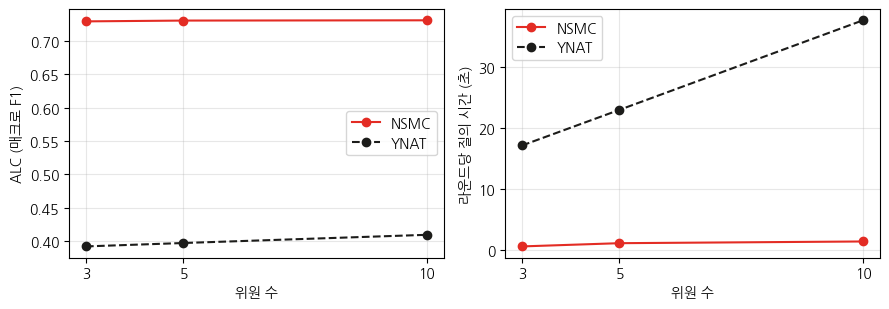

In [7]:
# ── 위원회 크기 그림 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for (name, g), c, ls in zip(size_table.groupby("data"), (ACCENT, INK), ("-", "--")):
    axes[0].plot(g.C, g.ALC, color=c, ls=ls, marker="o", label=name.upper())
    axes[1].plot(g.C, g.t_query, color=c, ls=ls, marker="o", label=name.upper())
axes[0].set(xlabel="위원 수", ylabel="ALC (매크로 F1)")
axes[1].set(xlabel="위원 수", ylabel="라운드당 질의 시간 (초)")
for ax in axes:
    ax.set_xticks(SIZES)
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig("out/ch04_committee_size.png", dpi=200)

In [8]:
# ── 배깅 위원회의 KL과 투표가 고른 샘플 ────
d = DATA["ynat"]
idx = np.random.default_rng(0).choice(len(d["y_pool"]), N_INIT, replace=False)
idx_u = np.setdiff1d(np.arange(len(d["y_pool"])), idx)
PC = committee_proba(train_bagging_committee(d["X_pool"][idx], d["y_pool"][idx], 5, 0), d["X_pool"][idx_u], d["n_classes"])
print(f"풀 전체: 합의 확률 최댓값 평균 {PC.mean(0).max(1).mean():.3f}")
for name, fn in [("KL 불일치", score_kl), ("투표 엔트로피", score_vote_entropy)]:
    top = np.argsort(-fn(PC))[:K]
    print(f"\n{name} 상위 {K}개: 합의 확률 최댓값 평균 {PC.mean(0)[top].max(1).mean():.3f}")
    for i in top[:5]:
        print("  ", d["texts"][idx_u[i]])
print("\nKL 불일치 1위 샘플의 위원별 확률")
print(PC[:, np.argmax(score_kl(PC))].round(2))

풀 전체: 합의 확률 최댓값 평균 0.230

KL 불일치 상위 50개: 합의 확률 최댓값 평균 0.420
   여행용 가방도 OK 인천공항도심 예약제 버스 운행
   검찰 기소 MBN 장대환 회장 사퇴 투명 경영하겠다종합
   국내 주식형 펀드서 하루 만에 자금 순유출
   국내 주식형 펀드 닷새만에 자금 순유출
   국내 주식형 펀드서 14거래일째 자금 순유출

투표 엔트로피 상위 50개: 합의 확률 최댓값 평균 0.189
   삼성 세계 이통사와 5G 협력 강화…유럽서도 서비스 시연
   한국 스마트폰 평균 도매가 60만원 육박…세계 2번째
   영화 1편 1초 전송 삼성 세계 최고성능 V낸드 SSD 출시
   멕시코서 울려 퍼질 아리랑…17일 대규모 야외 공연
   마사지숍서 현금 125만원 훔친 20대 구속

KL 불일치 1위 샘플의 위원별 확률
[[0.02 0.02 0.83 0.03 0.03 0.03 0.04]
 [0.11 0.14 0.18 0.11 0.13 0.15 0.18]
 [0.16 0.09 0.17 0.16 0.16 0.11 0.15]
 [0.03 0.03 0.77 0.03 0.04 0.04 0.06]
 [0.04 0.04 0.76 0.04 0.03 0.04 0.05]]


## 4.6 불확실성 샘플링과의 비교

Random, 3장의 엔트로피, 이 장의 최선 QBC 설정을 한 표에 놓는다. 엔트로피는 이 장에서 다시 돌려 3장 값과 같은지 대조한다.

In [9]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

nsmc  엔트로피 완료
nsmc 3장 대비 엔트로피 F1 최대 차이: 5.551115123125783e-17


ynat  엔트로피 완료
ynat 3장 대비 엔트로피 F1 최대 차이: 8.326672684688674e-17

nsmc 최선 QBC: 배깅5·투표
strategy    ALC  ALC_std  final     LE  t_query
  배깅5·투표 0.7469   0.0039 0.7876 1.2500   0.8810
  Random 0.7426   0.0034 0.7802 1.0000   0.0001
    엔트로피 0.7479   0.0055 0.7860 1.2121   0.0087
strategy    ALC  ALC_std  final     LE  t_query
  배깅5·투표 0.7480   0.0039 0.7876 1.2121   0.8810
  Random 0.7447   0.0020 0.7803 1.0000   0.0001
    엔트로피 0.7491   0.0051 0.7861 1.2121   0.0087

ynat 최선 QBC: 이종3·투표
strategy    ALC  ALC_std  final     LE  t_query
  이종3·투표 0.6089   0.0096 0.7172 1.8182   3.4069
  Random 0.5335   0.0068 0.6500 1.0000   0.0001
    엔트로피 0.6164   0.0048 0.7202 2.0000   0.0250
strategy    ALC  ALC_std  final     LE  t_query
  이종3·투표 0.6062   0.0132 0.7229 2.0000   3.4069
  Random 0.5082   0.0080 0.6374 1.0000   0.0001
    엔트로피 0.6221   0.0069 0.7268 2.3529   0.0250


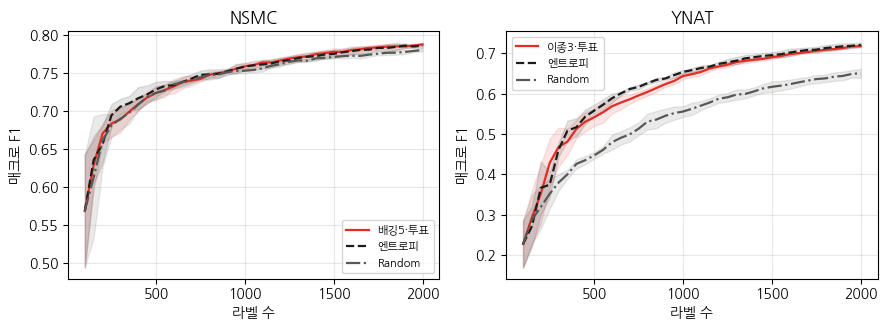

In [10]:
# ── 3장 전략과의 비교 ────
all_res = {}
for name, d in DATA.items():
    ent = run_strategies({"엔트로피": make_score_query(score_entropy)}, d)
    prev = pd.read_csv(f"results/ch03_{name}.csv")
    print(name, "3장 대비 엔트로피 F1 최대 차이:", np.abs(prev[prev.strategy == "엔트로피"].f1.values - ent.f1.values).max())
    all_res[name] = pd.concat([res[name], size_res[name][size_res[name].strategy == "배깅10·KL"], ent], ignore_index=True)
    all_res[name].to_csv(f"results/ch04_{name}.csv", index=False)

for name, r in all_res.items():
    s = summarize(r, "f1")
    best = s[~s.strategy.isin(["Random", "엔트로피"])].sort_values("ALC").strategy.iloc[-1]
    print(f"\n{name} 최선 QBC: {best}")
    print(s[s.strategy.isin(["Random", "엔트로피", best])].to_string(index=False))
    print(summarize(r[r.strategy.isin(["Random", "엔트로피", best])], "acc").to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, r) in zip(axes, all_res.items()):
    s = summarize(r, "f1")
    best = s[~s.strategy.isin(["Random", "엔트로피"])].sort_values("ALC").strategy.iloc[-1]
    order = [best, "엔트로피", "Random"]
    plot_curves(pd.concat([r[r.strategy == o] for o in order]), "f1", ax, name.upper())
fig.tight_layout()
fig.savefig("out/ch04_curves.png", dpi=200)